<a href="https://colab.research.google.com/github/Khlon-Stepan/Anytask-AESC-Homework/blob/main/EGE0711.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Кластеризация ЕГЭ (8.5 если сделаны все задачи)

Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

def read_data(filename):
    df_raw = pd.read_excel(filename, header=None)
    if isinstance(df_raw.iloc[0, 0], str):
        df = pd.read_excel(filename)
    else:
        df = df_raw
    df.columns = ['x', 'y']
    return df

def find_cluster_center(pts, metric='euclid'):
    best_pt = None
    min_sum = float('inf')

    for p in pts:
        if metric == 'euclid':
            d = np.sum(np.sqrt(np.sum((pts - p) ** 2, axis=1)))
        else:
            d = np.sum(np.sum(np.abs(pts - p), axis=1))
        if d < min_sum:
            min_sum = d
            best_pt = p
    return best_pt

def solve_and_plot(filename, dist_name, split_func):
    df = read_data(filename)
    clusters = split_func(df)

    centers = []
    plt.figure(figsize=(6, 5))
    colors = ['tab:blue', 'tab:orange', 'tab:green']

    for i, c in enumerate(clusters):
        pts = c[['x', 'y']].values
        center = find_cluster_center(pts, dist_name)
        centers.append(center)
        plt.scatter(pts[:, 0], pts[:, 1], s=4, color=colors[i], label=f'Кластер {i+1}')
        plt.scatter(center[0], center[1], s=60, color='red', marker='x')

    mean_x = np.mean([p[0] for p in centers])
    mean_y = np.mean([p[1] for p in centers])
    ans_x = int(mean_x * 1000)
    ans_y = int(mean_y * 1000)

    plt.title(f"{filename} | Ответ: {ans_x}, {ans_y}")
    plt.legend()
    plt.grid(True)
    plt.show()

    print(f"[{filename}] Ответ (* 1000): X = {ans_x}, Y = {ans_y}")

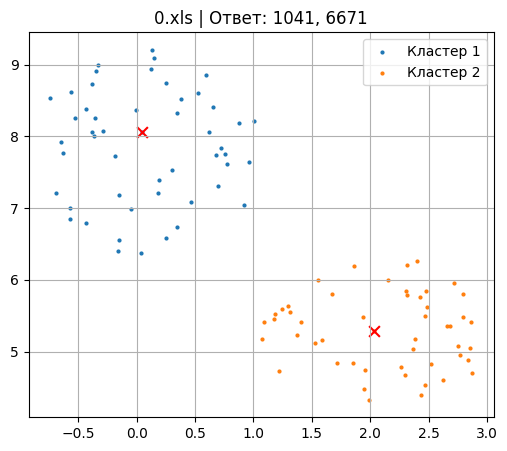

[0.xls] Ответ (* 1000): X = 1041, Y = 6671


In [56]:
solve_and_plot('0.xls', 'euclid', lambda df: [
    df[df['y'] > 6.3],
    df[df['y'] <= 6.3]
])

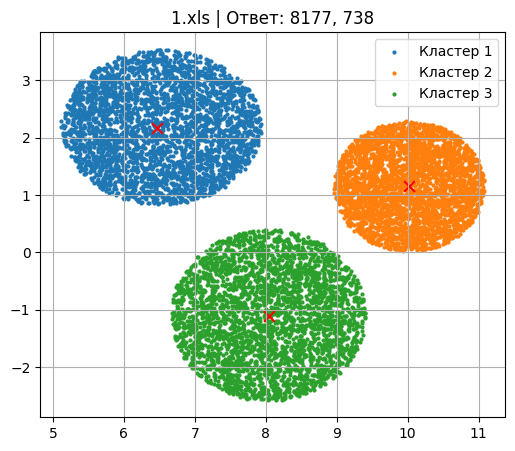

[1.xls] Ответ (* 1000): X = 8177, Y = 738


In [57]:
solve_and_plot('1.xls', 'euclid', lambda df: [
    df[(df['x'] < 8) & (df['y'] > 0.7)],       # Верхний левый
    df[(df['x'] > 8.5) & (df['y'] > -df['x']+9)], # Правый # прямая через точки (8.5 , 1) и (10 , -0.5)
    df[(df['y'] < 0.5) & (df['y'] < -df['x']+9)]  # Нижний
])

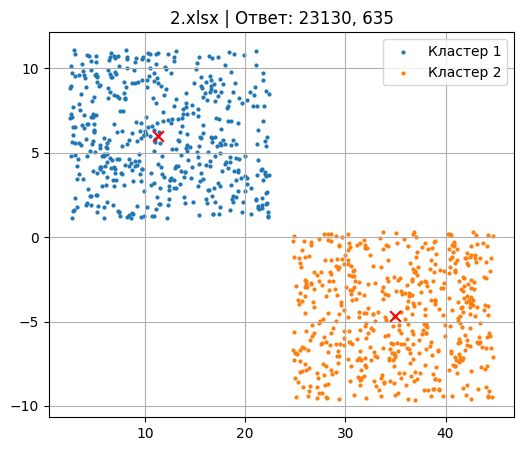

[2.xlsx] Ответ (* 1000): X = 23130, Y = 635


In [58]:
solve_and_plot('2.xlsx', 'euclid', lambda df: [
    df[df['x'] < 23],
    df[df['x'] >= 23]
])

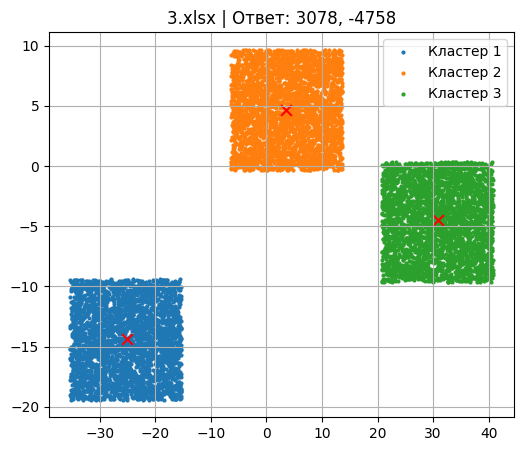

[3.xlsx] Ответ (* 1000): X = 3078, Y = -4758


In [59]:
solve_and_plot('3.xlsx', 'manhattan', lambda df: [
    df[df['x'] < -10],
    df[(df['x'] >= -10) & (df['x'] <= 15)],
    df[df['x'] > 15]
])

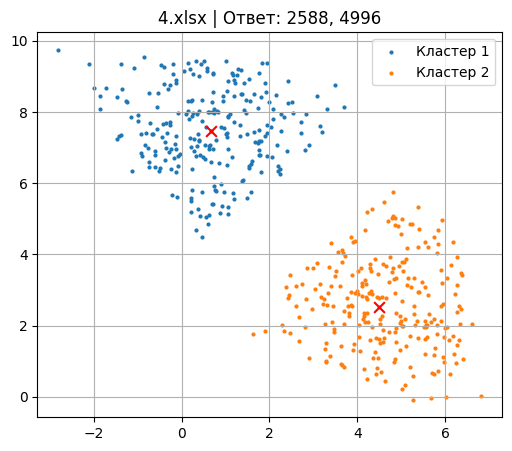

[4.xlsx] Ответ (* 1000): X = 2588, Y = 4996


In [60]:
solve_and_plot('4.xlsx', 'manhattan', lambda df: [
    df[df['y'] > df['x'] + 2],   # Верхний треугольник # прямая через (0 , 2) и (6 , 8)
    df[df['y'] < df['x'] + 2]   # Нижний треугольник
])

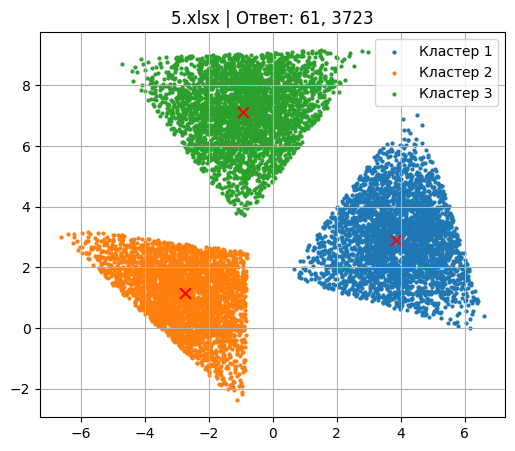

[5.xlsx] Ответ (* 1000): X = 61, Y = 3723


In [61]:
solve_and_plot('5.xlsx', 'euclid', lambda df: [
    df[(df['x'] > 0) & (df['y'] < 1.5*df['x']+2)], # правый # прямая через (0 , 2) и (4 , 8)
    df[(df['x'] < 0) & (df['y'] < -df['x']+2)], # нижний # прямая через (0 , 0) и (-2 , 4)
    df[(df['y'] > -df['x']+2) & (df['y'] > 1.5*df['x']+2)] # верхний # выше двух прямые в первый двух кластерах
])

# Кластеризация (0.75 за каждый алгоритм на всех данных)

На предложенных распределениях данных проверьте предложенные алгоритмы. Постройте графики кластеризации для каждой пары алгоритм-данные, разные кластеры покрасьте разным цветом. Воспользуйтесь sklearn реализациями. Параметры кластеризации для разных алгоритмов подберите такие, чтобы алгоритмы можно было сравнивать (по возможности одинаковое количество кластеров и т.д.)

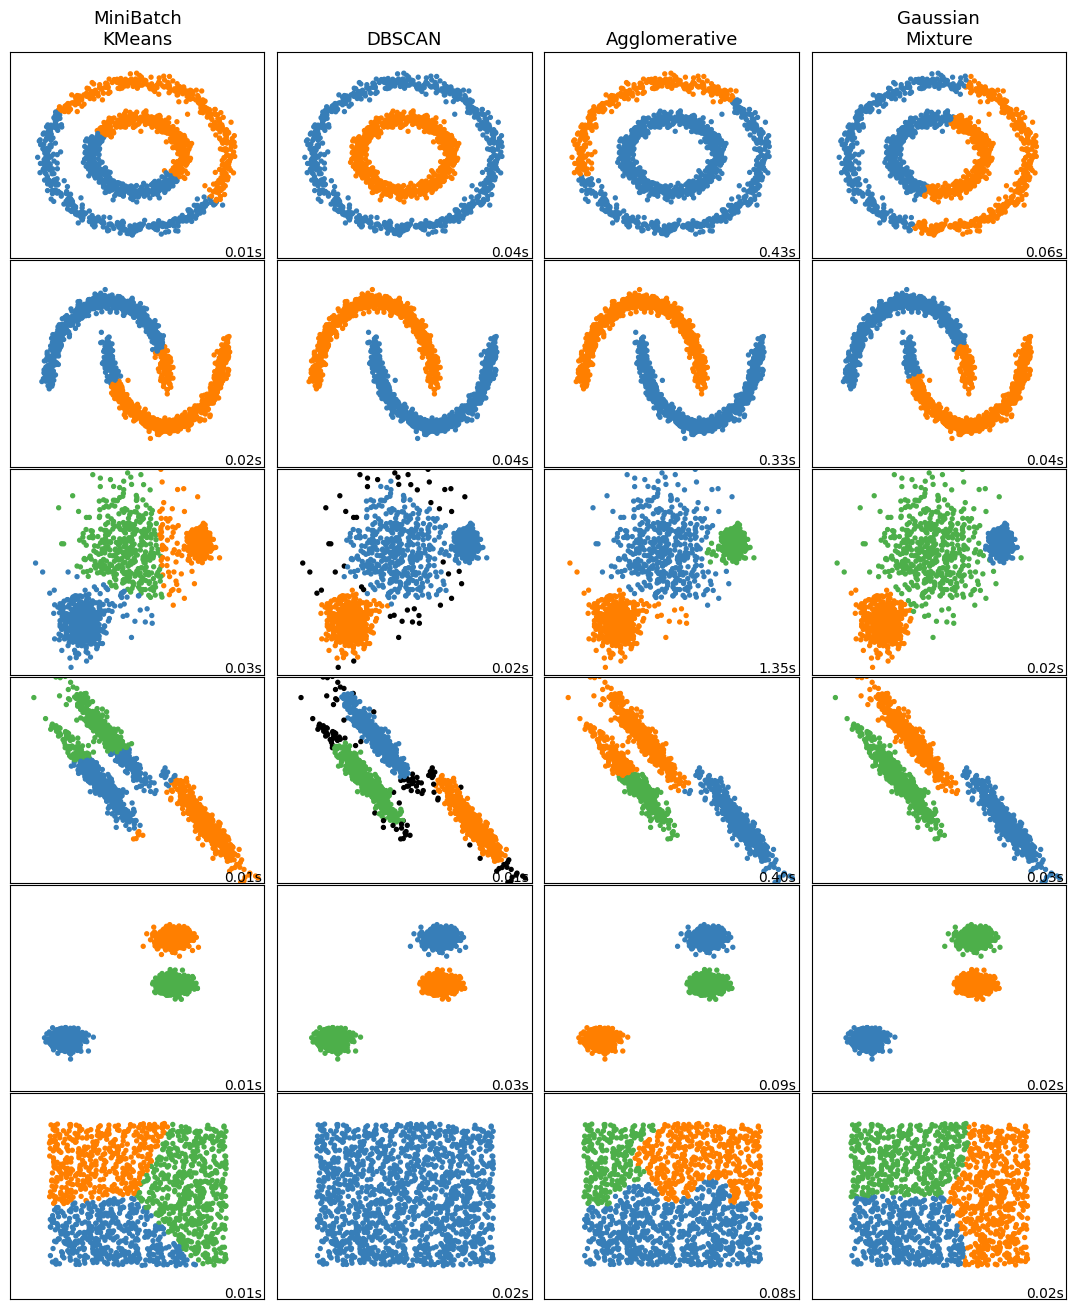

In [ ]:
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt

from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from itertools import cycle, islice

np.random.seed(0)

# ============
# 1. Генерация тестовых наборов данных
# ============
n_samples = 1500
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = np.random.rand(n_samples, 2), None

# Анизотропные данные (вытянутые кластеры)
random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

# Кластеры с разной дисперсией (плотностью)
varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)

# ============
# 2. Настройка параметров кластеризации
# ============
default_base = {
    "quantile": 0.3,
    "eps": 0.3,
    "damping": 0.9,
    "preference": -200,
    "n_neighbors": 10,
    "n_clusters": 3,
    "min_samples": 20,
    "xi": 0.05,
    "min_cluster_size": 0.1,
}

datasets_list = [
    (
        noisy_circles,
        {
            "damping": 0.77,
            "preference": -240,
            "quantile": 0.2,
            "n_clusters": 2,
            "min_samples": 20,
            "xi": 0.25,
        },
    ),
    (noisy_moons, {"damping": 0.75, "preference": -220, "n_clusters": 2}),
    (
        varied,
        {
            "eps": 0.18,
            "n_neighbors": 2,
            "min_samples": 5,
            "xi": 0.035,
            "min_cluster_size": 0.2,
        },
    ),
    (
        aniso,
        {
            "eps": 0.15,
            "n_neighbors": 2,
            "min_samples": 20,
            "xi": 0.1,
            "min_cluster_size": 0.2,
        },
    ),
    (blobs, {}),
    (no_structure, {}),
]

# Названия колонок на итоговом графике
algorithm_names = ["MiniBatch\nKMeans", "DBSCAN", "Agglomerative", "Gaussian\nMixture"]

plt.figure(figsize=(2 * len(algorithm_names) + 3, 13))
plt.subplots_adjust(
    left=0.02, right=0.98, bottom=0.001, top=0.96, wspace=0.05, hspace=0.01
)

plot_num = 1

# ============
# 3. Обучение моделей и построение графиков
# ============
for i_dataset, (dataset, algo_params) in enumerate(datasets_list):
    # Обновляем параметры для конкретного распределения
    params = default_base.copy()
    params.update(algo_params)

    X, y = dataset
    # Стандартизация (приведение к mean=0, std=1) для сопоставимости расстояний
    X = StandardScaler().fit_transform(X)

    # Матрица связности соседей для AgglomerativeClustering
    connectivity = kneighbors_graph(
        X, n_neighbors=params["n_neighbors"], include_self=False
    )
    connectivity = 0.5 * (connectivity + connectivity.T)

    # Инициализация 4 алгоритмов
    two_means = cluster.MiniBatchKMeans(
        n_clusters=params["n_clusters"], n_init="auto", random_state=0
    )
    dbscan = cluster.DBSCAN(
        eps=params["eps"], min_samples=params.get("min_samples", 5)
    )
    ward = cluster.AgglomerativeClustering(
        n_clusters=params["n_clusters"], linkage="ward", connectivity=connectivity
    )
    gmm = mixture.GaussianMixture(
        n_components=params["n_clusters"], covariance_type="full", random_state=0
    )

    clustering_algorithms = (
        ("MiniBatch\nKMeans", two_means),
        ("DBSCAN", dbscan),
        ("Agglomerative", ward),
        ("Gaussian\nMixture", gmm),
    )

    for name, algorithm in clustering_algorithms:
        t0 = time.time()
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore")
            algorithm.fit(X)
        t1 = time.time()

        # Получаем предсказанные метки кластеров
        if hasattr(algorithm, "labels_"):
            y_pred = algorithm.labels_.astype(int)
        else:
            y_pred = algorithm.predict(X)

        # Выбираем ячейку в таблице графиков
        plt.subplot(len(datasets_list), len(clustering_algorithms), plot_num)
        if i_dataset == 0:
            plt.title(name, size=13)

        # Палитра цветов для кластеров
        colors = np.array(
            list(
                islice(
                    cycle(
                        [
                            "#377eb8",
                            "#ff7f00",
                            "#4daf4a",
                            "#f781bf",
                            "#a65628",
                            "#984ea3",
                            "#999999",
                            "#e41a1c",
                            "#dede00",
                        ]
                    ),
                    int(max(y_pred) + 1),
                )
            )
        )
        # Шумовые точки DBSCAN (метка -1) будут черного цвета
        colors = np.append(colors, ["#000000"])
        plt.scatter(X[:, 0], X[:, 1], s=8, color=colors[y_pred])

        plt.xlim(-2.5, 2.5)
        plt.ylim(-2.5, 2.5)
        plt.xticks(())
        plt.yticks(())
        # Время работы алгоритма в правом нижнем углу
        plt.text(
            0.99,
            0.01,
            f"{(t1 - t0):.2f}s",
            transform=plt.gca().transAxes,
            size=10,
            horizontalalignment="right",
        )
        plot_num += 1

plt.show()